# Conditional Probability

Companion notebook for [Conditional Probability and Multiplication Rule](../../notes/probability/conditional_probability.md).

$P(A\mid B)=P(A\cap B)/P(B)$ restricts attention to the outcomes in $B$. We compute it by enumeration, apply the multiplication rule to card draws, test independence, and recreate the birthday problem.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from fractions import Fraction

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 3.5)

## 1. Conditioning as restriction of the sample space

With two dice, condition on "sum = 8": only 5 of the 36 pairs remain, and exactly one of them has first die 3, so $P(D_1=3\mid\text{sum}=8)=1/5$.

In [2]:
S = list(product(range(1, 7), repeat=2))
def cond(a, b):
    sb = [s for s in S if b(s)]
    return Fraction(sum(1 for s in sb if a(s)), len(sb))

print("P(first=3 | sum=8) =", cond(lambda s: s[0] == 3, lambda s: sum(s) == 8))
print("P(sum=8 | first=3) =", cond(lambda s: sum(s) == 8, lambda s: s[0] == 3))
print("P(first even | sum=7) =", cond(lambda s: s[0] % 2 == 0, lambda s: sum(s) == 7))

P(first=3 | sum=8) = 1/5
P(sum=8 | first=3) = 1/6
P(first even | sum=7) = 1/2


## 2. Multiplication rule: drawing without replacement

$P(A\cap B)=P(A)\,P(B\mid A)$. Two diamonds in a row: $\frac{13}{52}\cdot\frac{12}{51}=\frac1{17}$. We compare with a Monte Carlo estimate.

In [3]:
exact = Fraction(13, 52) * Fraction(12, 51)
deck = np.repeat(np.arange(4), 13)          # 0 = diamonds
trials = 100_000
hits = 0
for _ in range(trials):
    draw = rng.choice(52, size=2, replace=False)
    hits += (deck[draw] == 0).all()
print("exact   :", exact, "=", round(float(exact), 5))
print("simulate:", round(hits / trials, 5))

exact   : 1/17 = 0.05882
simulate: 0.0586


## 3. Independence

$A$ and $B$ are independent iff $P(A\cap B)=P(A)P(B)$. For integers 1..100, divisibility by 3 and by 7 are *not* independent; for 1..105 (a multiple of $3\cdot7$) they are.

In [4]:
def check(N):
    xs = range(1, N + 1)
    pA = Fraction(sum(1 for x in xs if x % 3 == 0), N)
    pB = Fraction(sum(1 for x in xs if x % 7 == 0), N)
    pAB = Fraction(sum(1 for x in xs if x % 21 == 0), N)
    return pA, pB, pAB, pA * pB == pAB

for N in (100, 105):
    pA, pB, pAB, ind = check(N)
    print(f"N={N}: P(A)={pA}, P(B)={pB}, P(A and B)={pAB}, P(A)P(B)={pA*pB} -> independent: {ind}")

N=100: P(A)=33/100, P(B)=7/50, P(A and B)=1/25, P(A)P(B)=231/5000 -> independent: False
N=105: P(A)=1/3, P(B)=1/7, P(A and B)=1/21, P(A)P(B)=1/21 -> independent: True


## 4. "At least one" via the complement

For independent trials, $P(\text{at least one})=1-\prod(1-p_i)$. Three rolls with at least one six: $1-(5/6)^3=91/216\approx0.4213$.

In [5]:
print("exact:", 1 - Fraction(5, 6) ** 3, "=", round(1 - (5 / 6) ** 3, 4))
sim = (rng.integers(1, 7, size=(200_000, 3)) == 6).any(axis=1).mean()
print("simulated:", round(sim, 4))

print("4 rolls     :", round(1 - (5 / 6) ** 4, 4))
print("24 double-6 :", round(1 - (35 / 36) ** 24, 4))

exact: 91/216 = 0.4213
simulated: 0.4209
4 rolls     : 0.5177
24 double-6 : 0.4914


## 5. The birthday problem

$P(\text{shared})=1-\prod_{i=0}^{n-1}\frac{365-i}{365}$. We tabulate it, find where it first exceeds $1/2$, and check by simulation.

first n with P > 0.5: 23  P = 0.5073
5 0.0271
10 0.1169
23 0.5073
30 0.7063
50 0.9704
simulated n=23: 0.5092


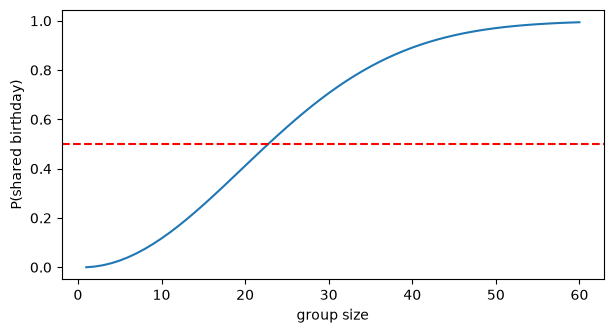

In [6]:
def p_shared(n):
    return 1 - np.prod((365 - np.arange(n)) / 365)

ns = np.arange(1, 61)
p = np.array([p_shared(n) for n in ns])
print("first n with P > 0.5:", ns[p > 0.5][0], " P =", round(p_shared(23), 4))
for n in (5, 10, 23, 30, 50):
    print(n, round(p_shared(n), 4))

sim = np.mean([len(set(rng.integers(0, 365, 23))) < 23 for _ in range(20000)])
print("simulated n=23:", round(sim, 4))

plt.plot(ns, p)
plt.axhline(0.5, color="red", linestyle="--")
plt.xlabel("group size"); plt.ylabel("P(shared birthday)")
plt.show()